<a href="https://colab.research.google.com/github/muralekarrtik2005-del/Machine-learning-Slot-C/blob/main/Vempati_Murale_Karrtik.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Exp 1:- Implement and demonstrate the FIND-S algorithm for finding the most specific hypothesis
based on a given set of training data samples.

In [ ]:
training_data = [
    ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change', 'No'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change', 'Yes']
]

num_attributes = len(training_data[0]) - 1 # Exclude the target concept column

print("Training Data:")
for example in training_data:
    print(example)

# Find the most specific hypothesis
hypothesis = find_s(training_data, num_attributes)

print(f"\nMost Specific Hypothesis: {hypothesis}")

Training Data:
['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes']
['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes']
['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change', 'No']
['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change', 'Yes']

Most Specific Hypothesis: ['Sunny', 'Warm', '?', 'Strong', '?', '?']


Exp 2:- For a given set of training data examples stored in a .CSV file, implement and demonstrate the
Candidate-Elimination algorithm in python to output a description of the set of all hypotheses
consistent with the training examples

In [ ]:
print("### Applying Candidate-Elimination Algorithm to Sample Dataset")

# Step 1: Define a suitable training dataset (Enjoy Sport-like)
# Each inner list: [Feat1, Feat2, ..., FeatN, Target (Yes/No)]
training_data_ce = [
    ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change', 'No'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change', 'Yes']
]

print("\nTraining data for Candidate-Elimination:")
for example in training_data_ce:
    print(example)

# Step 2 & 3: Call the candidate_elimination function and store results
S_final, G_final = candidate_elimination(training_data_ce)

# Step 4: Print the final S and G boundary sets
print("\n--- Final Result ---")
print(f"Final Specific Boundary (S): {S_final}")
print(f"Final General Boundary (G): {G_final}")

### Applying Candidate-Elimination Algorithm to Sample Dataset

Training data for Candidate-Elimination:
['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes']
['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes']
['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change', 'No']
['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change', 'Yes']

Initial S:  []
Initial G:  [['?', '?', '?', '?', '?', '?']]

Processing example 1: ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes']
S after example 1: [['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']]
G after example 1: [['?', '?', '?', '?', '?', '?']]

Processing example 2: ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes']
S after example 2: [['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']]
G after example 2: [['?', '?', '?', '?', '?', '?']]

Processing example 3: ['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change', 'No']
S after example 3: [['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']]
G after example 3: [['Sun

Exp 3:- Demonstrate the working of the decision tree based ID3 algorithm. Use an appropriate data set
for building the decision tree and apply this knowledge to classify a new sample.

Dataset:
     Outlook Temperature Humidity    Wind PlayTennis
0      Sunny         Hot     High    Weak         No
1      Sunny         Hot     High  Strong         No
2   Overcast         Hot     High    Weak        Yes
3       Rain        Mild     High    Weak        Yes
4       Rain        Cool   Normal    Weak        Yes
5       Rain        Cool   Normal  Strong         No
6   Overcast        Cool   Normal  Strong        Yes
7      Sunny        Mild     High    Weak         No
8      Sunny        Cool   Normal    Weak        Yes
9       Rain        Mild   Normal    Weak        Yes
10     Sunny        Mild   Normal  Strong        Yes
11  Overcast        Mild     High  Strong        Yes
12  Overcast         Hot   Normal    Weak        Yes
13      Rain        Mild     High  Strong         No


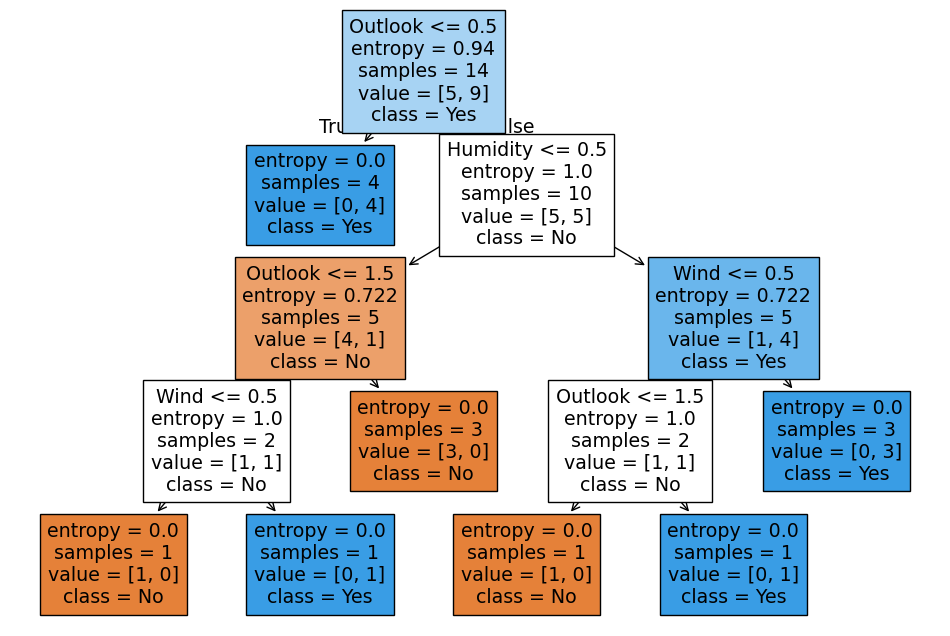

Prediction for new sample: No


In [ ]:
# Import libraries
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn import tree
import matplotlib.pyplot as plt

# Create PlayTennis dataset
data = {
    'Outlook': ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity': ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind': ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'PlayTennis': ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No']
}

# Convert to DataFrame
df = pd.DataFrame(data)

print("Dataset:")
print(df)

# Encode categorical values
le = LabelEncoder()
encoders = {}

for column in df.columns:
    enc = LabelEncoder()
    df[column] = enc.fit_transform(df[column])
    encoders[column] = enc

# Split features and target
X = df[['Outlook','Temperature','Humidity','Wind']]
y = df['PlayTennis']

# Train Decision Tree using entropy (ID3)
model = DecisionTreeClassifier(criterion="entropy")
model.fit(X, y)

# Plot Decision Tree
plt.figure(figsize=(12,8))
tree.plot_tree(model,
               feature_names=X.columns,
               class_names=encoders['PlayTennis'].classes_,
               filled=True)
plt.show()

# New sample to classify
# Example: Sunny, Cool, High, Strong
sample = {
    'Outlook': 'Sunny',
    'Temperature': 'Cool',
    'Humidity': 'High',
    'Wind': 'Strong'
}

# Convert sample to DataFrame
sample_df = pd.DataFrame([sample])

# Encode sample using same encoders
for column in sample_df.columns:
    sample_df[column] = encoders[column].transform(sample_df[column])

# Predict
prediction = model.predict(sample_df)

# Decode prediction
result = encoders['PlayTennis'].inverse_transform(prediction)

print("Prediction for new sample:", result[0])

Exp 4:- Build an Artificial Neural Network by implementing the Backpropagation algorithm and test the
same using appropriate data sets.

In [ ]:
# Import libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Convert output to one-hot encoding
Y = np.zeros((y.size, y.max()+1))
Y[np.arange(y.size), y] = 1

# Normalize the input features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split dataset into training and testing
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=1)

# Network structure
input_neurons = 4
hidden_neurons = 5
output_neurons = 3

learning_rate = 0.1
epochs = 5000

# Initialize weights randomly
np.random.seed(1)
W1 = np.random.randn(input_neurons, hidden_neurons)
W2 = np.random.randn(hidden_neurons, output_neurons)

# Sigmoid activation function
def sigmoid(x):
    return 1/(1+np.exp(-x))

# Derivative of sigmoid
def sigmoid_derivative(x):
    return x*(1-x)

# Training using Backpropagation
for i in range(epochs):

    # Forward propagation
    hidden_input = np.dot(X_train, W1)
    hidden_output = sigmoid(hidden_input)

    final_input = np.dot(hidden_output, W2)
    final_output = sigmoid(final_input)

    # Calculate error
    error = Y_train - final_output

    # Backpropagation
    d_output = error * sigmoid_derivative(final_output)
    error_hidden = d_output.dot(W2.T)
    d_hidden = error_hidden * sigmoid_derivative(hidden_output)

    # Update weights
    W2 += hidden_output.T.dot(d_output) * learning_rate
    W1 += X_train.T.dot(d_hidden) * learning_rate

# Testing phase
hidden_test = sigmoid(np.dot(X_test, W1))
output_test = sigmoid(np.dot(hidden_test, W2))

# Predicted class
predicted = np.argmax(output_test, axis=1)
actual = np.argmax(Y_test, axis=1)

# Accuracy
accuracy = np.mean(predicted == actual)

print("Predicted Classes:", predicted)
print("Actual Classes:", actual)
print("Model Accuracy:", accuracy)

Predicted Classes: [0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 2 0 2 1 0 0 1 2]
Actual Classes: [0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 1 0 2 1 0 0 1 2]
Model Accuracy: 0.9666666666666667


Exp 5:- Write a program for Implementation of K-Nearest Neighbours (K-NN) in Python

In [ ]:
# Import libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

# Load Breast Cancer dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Feature scaling (important for KNN)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create KNN model
k = 5
knn = KNeighborsClassifier(n_neighbors=k)

# Train model
knn.fit(X_train, y_train)

# Predict test data
y_pred = knn.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Predicted Values:", y_pred)
print("Actual Values:", y_test)
print("Model Accuracy:", accuracy)

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Predict a new sample
sample = [X_test[0]]
prediction = knn.predict(sample)

print("Prediction for sample:", prediction)

Predicted Values: [1 0 1 0 1 0 0 0 1 1 1 0 0 1 1 1 1 1 1 0 1 1 0 1 0 1 1 0 0 0 0 1 0 0 1 1 0
 1 1 1 1 1 1 1 1 0 1 1 1 0 0 0 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 0
 1 0 1 1 1 0 1 0 1 0 1 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0
 1 1 1]
Actual Values: [1 0 1 0 0 0 0 0 1 1 1 0 0 1 1 1 1 1 1 0 1 1 0 1 0 1 1 0 0 0 0 1 0 0 1 1 0
 1 0 1 1 1 1 1 1 0 1 1 1 0 0 0 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 0 1 1 1 1 0 0
 1 0 0 0 1 0 1 0 1 0 1 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0
 1 1 1]
Model Accuracy: 0.956140350877193
Confusion Matrix:
[[37  5]
 [ 0 72]]
Prediction for sample: [1]


Exp 6:- Write a program to implement Naïve Bayes algorithm in python and to display the results using
confusion matrix and accuracy.

In [ ]:
# Import libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score

# Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Create Naive Bayes model
model = GaussianNB()

# Train the model
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("Accuracy:", accuracy)

Confusion Matrix:
[[38  4]
 [ 2 70]]
Accuracy: 0.9473684210526315


Exp 7:- Write a program to implement Logistic Regression (LR) algorithm in python

In [ ]:
# Import libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score

# Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create Logistic Regression model
model = LogisticRegression()

# Train the model
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("Accuracy:", accuracy)

Confusion Matrix:
[[40  2]
 [ 1 71]]
Accuracy: 0.9736842105263158


Exp 8:- Write a program to implement Linear Regression (LR) algorithm in python

In [ ]:
# Import libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
data = load_diabetes()
X = data.data
y = data.target

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Model evaluation
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Predicted Values:", y_pred[:10])
print("Actual Values:", y_test[:10])
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Predicted Values: [119.14235853 110.77183282 185.03750644  68.00997114 171.05444208
 190.41916188 218.59009744 119.63375975 157.26867822 129.50082172]
Actual Values: [ 78. 152. 200.  59. 311. 178. 332. 132. 156. 135.]
Mean Squared Error: 2992.5812293010176
R2 Score: 0.4384316213369278


Exp 9:- Compare Linear and Polynomial Regression using Python

In [ ]:
# Import libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

# Load dataset
data = load_diabetes()
X = data.data
y = data.target

# Use only one feature for visualization
X = X[:, np.newaxis, 2]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# -------- Linear Regression --------
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

# -------- Polynomial Regression --------
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

y_pred_poly = poly_model.predict(X_test_poly)

# -------- Evaluation --------
linear_r2 = r2_score(y_test, y_pred_linear)
poly_r2 = r2_score(y_test, y_pred_poly)

print("Linear Regression R2 Score:", linear_r2)
print("Polynomial Regression R2 Score:", poly_r2)

Linear Regression R2 Score: 0.2512945795962107
Polynomial Regression R2 Score: 0.25104653987074776


Exp 10:- Write a Python Program to Implement Expectation & Maximization Algorithm

In [ ]:
# Import libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Load dataset
data = load_iris()
X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Create EM model using Gaussian Mixture
em_model = GaussianMixture(n_components=3, random_state=1)

# Train model
em_model.fit(X_train)

# Predict clusters
y_pred = em_model.predict(X_test)

print("Predicted Clusters:", y_pred)
print("Actual Classes:", y_test)

# Accuracy (approximate comparison)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Predicted Clusters: [0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 2 1 0 2 1 0 0 1 2]
Actual Classes: [0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 1 0 2 1 0 0 1 2]
Accuracy: 0.9666666666666667


Exp 11:- Write a program for the task of Credit Score Classification

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

data = pd.DataFrame({
    'Age': [25, 35, 45, 23, 52, 40, 29, 60, 33, 48, 27, 55],
    'Income': [25000, 50000, 75000, 20000, 90000, 65000, 30000, 100000, 45000, 80000, 28000, 95000],
    'Loan': [10000, 20000, 30000, 15000, 25000, 20000, 12000, 35000, 18000, 28000, 11000, 30000],
    'Credit_History': [1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1],
    'Score': ['Poor', 'Good', 'Good', 'Poor', 'Good', 'Good', 'Poor', 'Good', 'Good', 'Good', 'Poor', 'Good']
})

X = data.drop('Score', axis=1)
y = data['Score']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

new_data = pd.DataFrame([[30, 40000, 15000, 1]], columns=X.columns)
print("Credit Score:", model.predict(new_data)[0])

Accuracy: 1.0
Classification Report:
               precision    recall  f1-score   support

        Good       1.00      1.00      1.00         1
        Poor       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3

Confusion Matrix:
 [[1 0]
 [0 2]]
Credit Score: Good


Exp 12:-Implement Iris Flower Classification using KNN

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

sample = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(sample)

print("Predicted Flower:", iris.target_names[prediction[0]])

Accuracy: 1.0
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Predicted Flower: setosa


Exp 13:- Implement the Car Price Prediction Model using Python

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

data = pd.DataFrame({
    'Brand': ['Toyota', 'Honda', 'BMW', 'Audi', 'Hyundai', 'Toyota', 'Honda', 'BMW', 'Audi', 'Hyundai'],
    'Year': [2018, 2019, 2020, 2017, 2021, 2016, 2018, 2022, 2019, 2020],
    'Kilometers': [30000, 25000, 15000, 50000, 10000, 60000, 40000, 12000, 35000, 20000],
    'Fuel': ['Petrol', 'Diesel', 'Petrol', 'Diesel', 'Petrol', 'Diesel', 'Petrol', 'Petrol', 'Diesel', 'Petrol'],
    'Price': [800000, 900000, 2500000, 1800000, 700000, 600000, 750000, 3000000, 1900000, 850000]
})

X = data.drop('Price', axis=1)
y = data['Price']

categorical = ['Brand', 'Fuel']
numerical = ['Year', 'Kilometers']

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('num', 'passthrough', numerical)
])

model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

new_car = pd.DataFrame({
    'Brand': ['Toyota'],
    'Year': [2021],
    'Kilometers': [20000],
    'Fuel': ['Petrol']
})

print("Predicted Car Price:", model.predict(new_car)[0])

Mean Absolute Error: 352250.0
R2 Score: 0.15380749999999999
Predicted Car Price: 868500.0


Exp 14:- Implement House price Prediction using appropriate machine learning algorithm

Mean Squared Error: 61130000000.0
Mean Absolute Error: 191000.0
R2 Score: 0.93887
Predicted House Price: 3973000.0


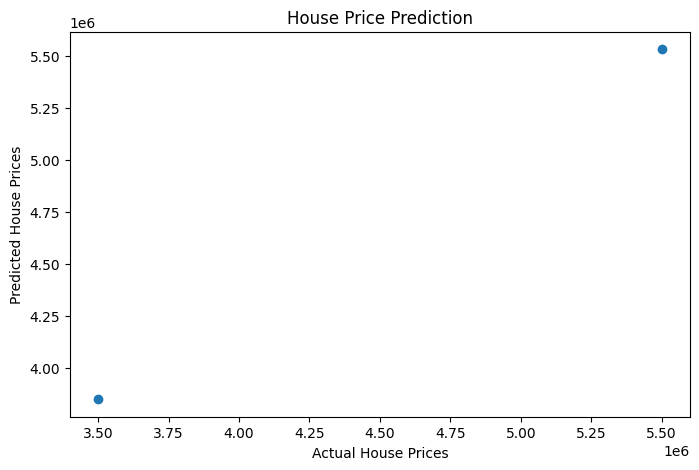

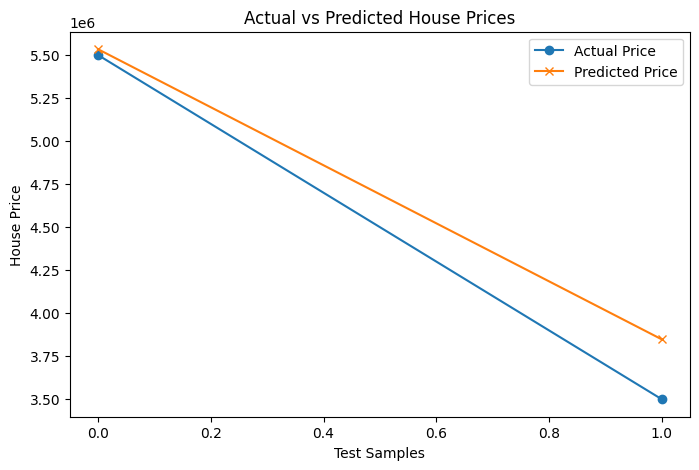

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

data = pd.DataFrame({
    'Area': [1000, 1500, 1800, 2000, 1200, 2500, 3000, 1600, 2200, 2800],
    'Bedrooms': [2, 3, 3, 4, 2, 4, 5, 3, 4, 5],
    'Bathrooms': [1, 2, 2, 3, 1, 3, 4, 2, 3, 3],
    'Age': [10, 5, 8, 3, 15, 2, 1, 7, 4, 2],
    'Price': [2500000, 3500000, 4000000, 5000000, 2800000, 6500000, 8000000, 3800000, 5500000, 7500000]
})

X = data.drop('Price', axis=1)
y = data['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(n_estimators=100, random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

new_house = pd.DataFrame(
    [[1800, 3, 2, 5]],
    columns=X.columns
)

predicted_price = model.predict(new_house)

print("Predicted House Price:", predicted_price[0])

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("House Price Prediction")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(y_test.values, label="Actual Price", marker='o')
plt.plot(y_pred, label="Predicted Price", marker='x')
plt.xlabel("Test Samples")
plt.ylabel("House Price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.show()

Exp 15:- Implement Iris Flower Classification using Naive Bayes classifier

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

sample = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(sample)

print("Predicted Flower:", iris.target_names[prediction[0]])

Accuracy: 1.0
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Predicted Flower: setosa


Exp 16:- Compare different types Classification Algorithms and evaluate their performance.

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier()),
    'Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'SVM': make_pipeline(StandardScaler(), SVC()),
    'Random Forest': RandomForestClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("\nAlgorithm:", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))


Algorithm: KNN
Accuracy: 1.0
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Algorithm: Naive Bayes
Accuracy: 1.0
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Algorithm

Exp 17:- Implement Mobile Price Prediction using appropriate machine learning algorithm

Accuracy: 1.0
Confusion Matrix:

[[1 0 0]
 [0 1 0]
 [0 0 1]]
Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           2       1.00      1.00      1.00         1
           3       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3

Predicted Price Range: 2
Mobile Price Category: High Cost


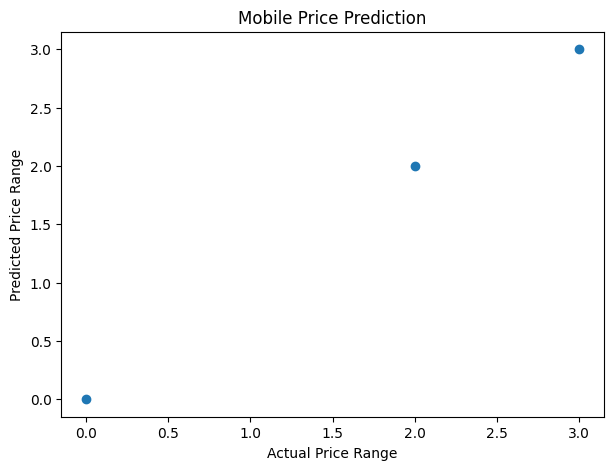

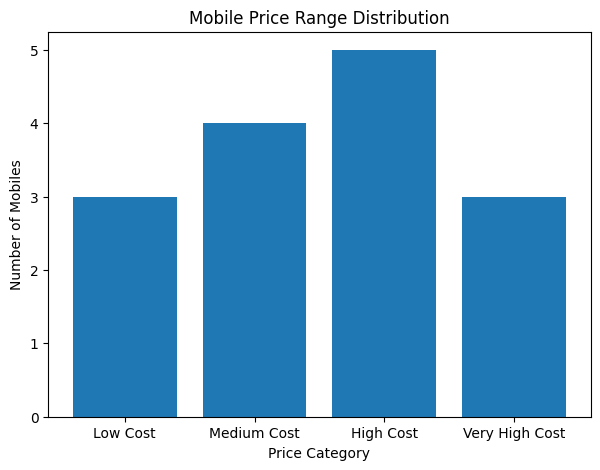

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = pd.DataFrame({
    'RAM': [2, 4, 6, 8, 12, 3, 4, 8, 6, 12, 2, 8, 4, 6, 12],
    'Battery': [2500, 3000, 4000, 4500, 5000, 2800, 3500, 4800, 4200, 5000, 2600, 4500, 3200, 4000, 5200],
    'Camera': [8, 12, 16, 48, 64, 8, 13, 50, 32, 108, 5, 48, 16, 32, 108],
    'Storage': [16, 32, 64, 128, 256, 16, 32, 128, 64, 256, 16, 128, 32, 64, 256],
    'Price_Range': [0, 1, 1, 2, 3, 0, 1, 2, 2, 3, 0, 2, 1, 2, 3]
})

X = data.drop('Price_Range', axis=1)
y = data['Price_Range']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Confusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:\n")
print(classification_report(y_test, y_pred))

new_mobile = pd.DataFrame(
    [[8, 5000, 64, 128]],
    columns=X.columns
)

prediction = model.predict(new_mobile)

price_ranges = {
    0: "Low Cost",
    1: "Medium Cost",
    2: "High Cost",
    3: "Very High Cost"
}

print("Predicted Price Range:", prediction[0])
print("Mobile Price Category:", price_ranges[prediction[0]])

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price Range")
plt.ylabel("Predicted Price Range")
plt.title("Mobile Price Prediction")
plt.show()

plt.figure(figsize=(7, 5))
plt.bar(
    ["Low Cost", "Medium Cost", "High Cost", "Very High Cost"],
    data['Price_Range'].value_counts().sort_index().values
)
plt.xlabel("Price Category")
plt.ylabel("Number of Mobiles")
plt.title("Mobile Price Range Distribution")
plt.show()

Exp 18:- Implement Perceptron based IRIS classification

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(
    StandardScaler(),
    Perceptron(max_iter=1000, random_state=42)
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

sample = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(sample)

print("Predicted Flower:", iris.target_names[prediction[0]])

Accuracy: 0.9333333333333333
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  2  9]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.82      1.00      0.90         9
           2       1.00      0.82      0.90        11

    accuracy                           0.93        30
   macro avg       0.94      0.94      0.93        30
weighted avg       0.95      0.93      0.93        30

Predicted Flower: setosa


Exp 19:- Implementation of Naive Bayes classification for Bank Loan prediction

Accuracy: 1.0
Confusion Matrix:
[[1 0]
 [0 5]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         5

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

Loan Status: Yes


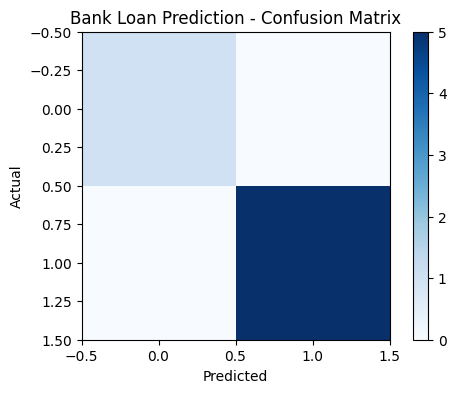

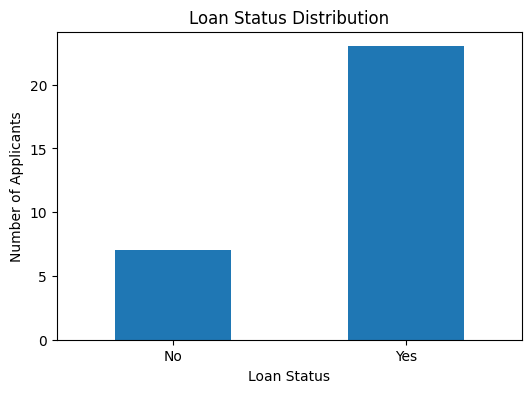

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = pd.DataFrame({
    'Age': [25, 35, 45, 28, 50, 40, 30, 55, 32, 48,
            26, 60, 38, 42, 29, 52, 33, 47, 36, 58,
            24, 44, 39, 51, 31, 46, 27, 56, 34, 49],
    'Income': ['Low', 'High', 'High', 'Medium', 'High',
               'Medium', 'Low', 'High', 'Medium', 'High',
               'Low', 'High', 'Medium', 'High', 'Low',
               'High', 'Medium', 'High', 'Medium', 'High',
               'Low', 'High', 'Medium', 'High', 'Low',
               'High', 'Low', 'High', 'Medium', 'High'],
    'Employment': ['No', 'Yes', 'Yes', 'Yes', 'Yes',
                   'Yes', 'No', 'Yes', 'Yes', 'Yes',
                   'No', 'Yes', 'Yes', 'Yes', 'No',
                   'Yes', 'Yes', 'Yes', 'Yes', 'Yes',
                   'No', 'Yes', 'Yes', 'Yes', 'No',
                   'Yes', 'No', 'Yes', 'Yes', 'Yes'],
    'Credit_History': ['Poor', 'Good', 'Good', 'Good', 'Good',
                       'Good', 'Poor', 'Good', 'Good', 'Good',
                       'Poor', 'Good', 'Good', 'Good', 'Poor',
                       'Good', 'Good', 'Good', 'Good', 'Good',
                       'Poor', 'Good', 'Good', 'Good', 'Poor',
                       'Good', 'Poor', 'Good', 'Good', 'Good'],
    'Loan_Status': ['No', 'Yes', 'Yes', 'Yes', 'Yes',
                    'Yes', 'No', 'Yes', 'Yes', 'Yes',
                    'No', 'Yes', 'Yes', 'Yes', 'No',
                    'Yes', 'Yes', 'Yes', 'Yes', 'Yes',
                    'No', 'Yes', 'Yes', 'Yes', 'No',
                    'Yes', 'No', 'Yes', 'Yes', 'Yes']
})

encoders = {}

for column in data.columns:
    le = LabelEncoder()
    data[column] = le.fit_transform(data[column])
    encoders[column] = le

X = data.drop('Loan_Status', axis=1)
y = data['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

new_data = pd.DataFrame({
    'Age': [35],
    'Income': [encoders['Income'].transform(['High'])[0]],
    'Employment': [encoders['Employment'].transform(['Yes'])[0]],
    'Credit_History': [encoders['Credit_History'].transform(['Good'])[0]]
})

prediction = model.predict(new_data)

loan_status = encoders['Loan_Status'].inverse_transform(prediction)

print("Loan Status:", loan_status[0])

plt.figure(figsize=(6, 4))
plt.imshow(confusion_matrix(y_test, y_pred), cmap='Blues')
plt.title("Bank Loan Prediction - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

plt.figure(figsize=(6, 4))
pd.Series(y).value_counts().sort_index().plot(kind='bar')
plt.title("Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.xticks([0, 1], ['No', 'Yes'], rotation=0)
plt.show()

Exp 20:- Implement Future Sales Prediction using a suitable machine learning algorithm

Mean Absolute Error: 152.02981482992695
Mean Squared Error: 31932.8456517509
R2 Score: -1.0531071165285932


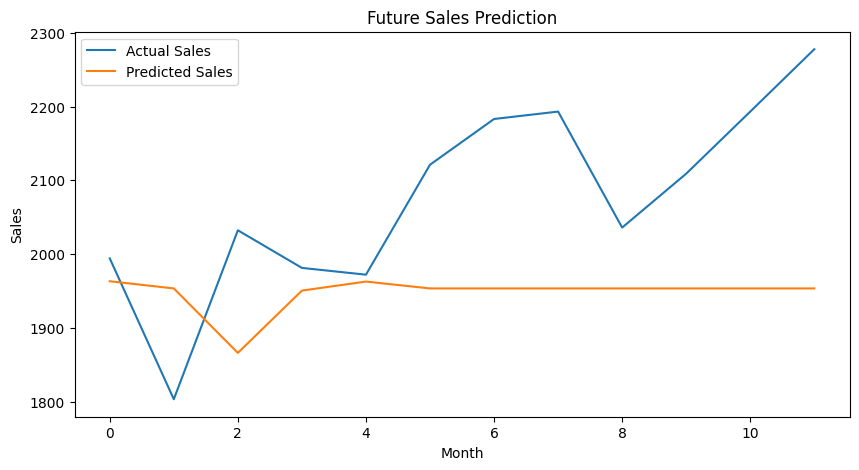

Predicted Future Sales: 1953.6899454339293


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)

months = 60

sales = 1000 + np.arange(months) * 20 + np.random.normal(0, 100, months)

data = pd.DataFrame({
    'Month': np.arange(1, months + 1),
    'Sales': sales
})

data['Lag1'] = data['Sales'].shift(1)
data['Lag2'] = data['Sales'].shift(2)
data['Lag3'] = data['Sales'].shift(3)
data['Rolling_Mean'] = data['Sales'].shift(1).rolling(3).mean()

data = data.dropna()

X = data[['Month', 'Lag1', 'Lag2', 'Lag3', 'Rolling_Mean']]
y = data['Sales']

split = int(len(data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]
y_train = y.iloc[:split]
y_test = y.iloc[split:]

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

plt.figure(figsize=(10, 5))
plt.plot(y_test.values, label='Actual Sales')
plt.plot(y_pred, label='Predicted Sales')
plt.title("Future Sales Prediction")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.show()

last_month = data.iloc[-1]

next_month = pd.DataFrame([{
    'Month': last_month['Month'] + 1,
    'Lag1': last_month['Sales'],
    'Lag2': last_month['Lag1'],
    'Lag3': last_month['Lag2'],
    'Rolling_Mean': np.mean([
        last_month['Sales'],
        last_month['Lag1'],
        last_month['Lag2']
    ])
}])

future_sales = model.predict(next_month)

print("Predicted Future Sales:", future_sales[0])